# Tentativo 14 · 2. Classificazione: feature, ModernBERT troncato, ModernBERT a pezzi

**La domanda** (proposta di Fabio): ModernBERT legge al più 1024 token per articolo e il resto lo butta. Se
**spezziamo ogni articolo in pezzi**, facciamo valutare ogni pezzo e poi mettiamo insieme i voti, il transformer legge
tutto il testo. Va meglio? E batte il classificatore a feature (TF-IDF), che finora non abbiamo mai battuto?

Usiamo il dataset del notebook 1 (testate politiche, NewsGuard 2026, versione semplice) e gli stessi 5 fold per tutti
i modelli. **Ogni testata è valutata** (una volta, quando il suo fold fa da test) e tutte pesano uguale.

In [1]:
DATASET_DIR = "Results/dataset"            # il dataset del notebook 1
CACHE_DIR = "Results/cache"                # le previsioni dei modelli (se ci sono si caricano)
OUT_DIR = "Results/classificazione"

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import funzioni as F

DATASET, CACHE, OUT = Path(DATASET_DIR), Path(CACHE_DIR), Path(OUT_DIR)
GRAFICI = OUT / "grafici"; GRAFICI.mkdir(parents=True, exist_ok=True)

BLU, ARANCIO, VERDE, GRIGIO = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
    "patch.force_edgecolor": True, "patch.edgecolor": "#fcfcfb", "patch.linewidth": 0.6,
})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)

def mostra(nome, griglia="y"):
    """Mostra il grafico (griglia solo sull'asse dei valori) e lo salva anche in PNG, per le slide."""
    for a in plt.gcf().axes:
        a.grid(False); a.grid(axis=griglia)
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

CACHE.mkdir(parents=True, exist_ok=True)
def registra(messaggio):
    """Stampa e annota l'avanzamento dell'addestramento (in Results/cache/avanzamento.log, per seguirlo dal PC)."""
    print(messaggio, flush=True)
    with open(CACHE / "avanzamento.log", "a") as f:
        f.write(f"{pd.Timestamp.now():%Y-%m-%d %H:%M}  {messaggio}\n")

## 1. Il dataset
Quello preparato nel notebook 1: testate politiche, livello NewsGuard 2026, 5 fold (un gruppo in un solo fold).

In [3]:
# 1.1 articoli e testate
art = pd.read_csv(DATASET / "articoli.csv.gz")
t = pd.read_csv(DATASET / "testate.csv", index_col="domain")
art["livello"] = art.label.map(dict(enumerate(F.LIVELLI)))
t["valutazione"], t["peso"] = True, 1.0          # tutte le testate si valutano e pesano uguale (colonne usate dalle funzioni)
art["valutazione"], art["peso"] = True, 1.0
print(f"{len(art):,} articoli di {len(t)} testate in {t.gruppo.nunique()} gruppi")
pd.crosstab(t.fold, t.livello, margins=True, margins_name="totale")

42,219 articoli di 323 testate in 223 gruppi


livello,l1,l2,l3,l4,l5,totale
fold,,,,,,
1,11,19,8,19,8,65
2,11,19,7,20,8,65
3,11,18,7,20,9,65
4,11,18,7,20,8,64
5,10,19,7,19,9,64
totale,54,93,36,98,42,323


## 2. Quanto testo resta fuori da ModernBERT

ModernBERT spezza il testo in **token** (pezzi di parola) e ne legge al più **1024**: tutto quello che viene dopo si
perde. Contiamo i token di ogni articolo.

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


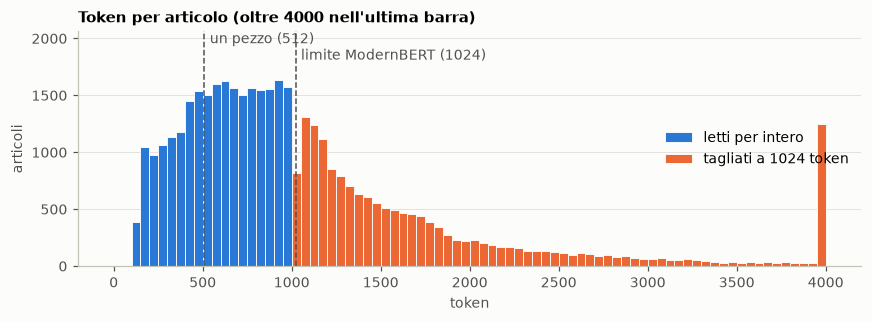

In [4]:
# 2.1 i token di ogni articolo
from transformers import AutoTokenizer, logging
logging.set_verbosity_error()                      # niente avvisi sulla lunghezza: qui contiamo soltanto i token
tok = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
art["ids"] = tok(art.text.tolist(), add_special_tokens=False)["input_ids"]
art["token"] = art.ids.str.len()

bins = np.arange(0, 4001, 50)
plt.hist(art.token.clip(upper=4000)[art.token <= 1022], bins, color=BLU, label="letti per intero")
plt.hist(art.token.clip(upper=4000)[art.token > 1022], bins, color=ARANCIO, label="tagliati a 1024 token")
plt.ylim(0, plt.ylim()[1] * 1.2)
for x, s, h in [(510, "un pezzo (512)", 0.95), (1022, "limite ModernBERT (1024)", 0.88)]:
    plt.axvline(x, color=GRIGIO, ls="--", lw=1); plt.text(x + 30, plt.ylim()[1] * h, s, color=GRIGIO)
plt.title("Token per articolo (oltre 4000 nell'ultima barra)"); plt.xlabel("token"); plt.ylabel("articoli"); plt.legend(loc="center right")
mostra("2_token")

In [5]:
# 2.2 per livello: quanti articoli superano 1024 token e quanto testo si perde
fuori = (art.token - 1022).clip(lower=0)                                          # token oltre il limite (1024 meno i 2 speciali)
riassunto = pd.DataFrame({
    "token (mediana)": art.groupby("livello").token.median().round(0),
    "oltre 512 token": (art.token > 510).groupby(art.livello).mean().round(2),
    "oltre 1024 token": (art.token > 1022).groupby(art.livello).mean().round(2),
    "testo perso (media)": (fuori / art.token).groupby(art.livello).mean().round(2),
})
riassunto.loc["tutti"] = [art.token.median(), round((art.token > 510).mean(), 2), round((art.token > 1022).mean(), 2), round((fuori / art.token).mean(), 2)]
print(f"in tutto resta fuori il {fuori.sum() / art.token.sum():.1%} dei token del dataset")
riassunto

in tutto resta fuori il 34.6% dei token del dataset


,token (mediana),oltre 512 token,oltre 1024 token,testo perso (media)
livello,,,,
l1,710.0,0.67,0.32,0.11
l2,910.0,0.82,0.37,0.10
l3,741.0,0.73,0.31,0.10
l4,925.0,0.80,0.43,0.16
l5,1198.0,0.86,0.59,0.25
tutti,896.0,0.78,0.40,0.14


Le testate più affidabili (l4, l5) scrivono articoli più lunghi: sono quelle che perdono più testo.

## 3. Come si spezza un articolo

Pezzi da **512 token** (510 di testo + 2 speciali) che partono ogni **446 token**: due pezzi vicini hanno **64 token in
comune**, così una frase tagliata a metà sta intera in uno dei due. Un articolo corto resta un pezzo solo.

In [6]:
# 3.1 un esempio: un articolo di circa 1500 token
esempio = art.iloc[(art.token - 1500).abs().argmin()]
pezzi = F.unita(esempio.ids, 510, passo=446)
print(f"{esempio.domain}: {esempio.token} token → {len(pezzi)} pezzi\n")
inizio = 0
for k, p in enumerate(pezzi):
    print(f"pezzo {k + 1}: token {inizio}–{inizio + len(p) - 1} ({len(p)} token): «{tok.decode(p[:12]).strip()} …»")
    inizio += 446

alphanews.org: 1500 token → 4 pezzi

pezzo 1: token 0–509 (510 token): «The Minnesota Senate is on the ballot for the first time since …»
pezzo 2: token 446–955 (510 token): «just when the DFL took control of all three branches of …»
pezzo 3: token 892–1401 (510 token): «Bureau of Criminal Apprehension. The bill passed the Senate …»
pezzo 4: token 1338–1499 (162 token): «tape that has stalled projects for decades and bring good-pay …»


127,719 pezzi per 42,219 articoli; per articolo: mediana 2, media 3.0; con un solo pezzo: 22%


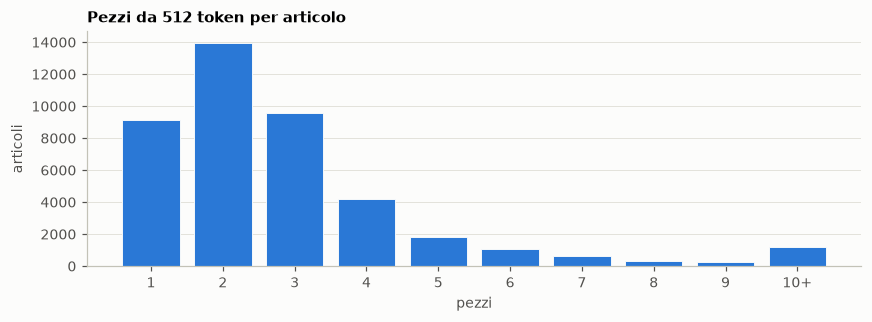

In [7]:
# 3.2 tutti gli articoli in pezzi
righe = []
for a, d, ids in zip(art.article_id, art.domain, art.ids):
    for k, pezzo in enumerate(F.unita(ids, 510, passo=446)):
        righe.append((a, d, k, pezzo, len(pezzo)))
Up = pd.DataFrame(righe, columns=["article_id", "domain", "pezzo", "ids", "token"])
n_pezzi = Up.groupby("article_id").size()
print(f"{len(Up):,} pezzi per {len(art):,} articoli; per articolo: mediana {n_pezzi.median():.0f}, media {n_pezzi.mean():.1f}; "
      f"con un solo pezzo: {(n_pezzi == 1).mean():.0%}")

conta = n_pezzi.clip(upper=10).value_counts().sort_index()
plt.bar(conta.index.astype(str).str.replace("10", "10+"), conta, color=BLU)
plt.title("Pezzi da 512 token per articolo"); plt.xlabel("pezzi"); plt.ylabel("articoli")
mostra("3_pezzi")

## 4. I tre modelli

Per ogni fold si addestra sulle testate degli altri 4 fold e si predicono le testate del fold. Gli stessi
fold per tutti. Le previsioni sono state calcolate una volta sola (ModernBERT: circa 1 ora e mezza su GPU) e salvate in
`Results/cache/`: se ci sono si caricano, altrimenti il codice qui sotto le ricalcola.

**1. Classificatore a feature** (il riferimento): TF-IDF di parole e coppie di parole (al più 100.000) + regressione
logistica (classi bilanciate), C scelto con una validazione interna per gruppi. Testata = **voto di maggioranza** dei suoi articoli.

In [8]:
# 4.1 classificatore a feature: probabilità dei 5 livelli per ogni articolo di test
f = CACHE / "feature_articoli.csv"
if f.exists():
    pf = pd.read_csv(f)
else:
    dati = art[["article_id", "domain", "text", "label", "gruppo", "valutazione", "fold", "peso"]]
    pf, scelti = F.classificatore_feature(dati)
    pf.to_csv(f, index=False)
print(f"{len(pf):,} articoli di test di {pf.domain.nunique()} testate")
pf.head(3).round(3)

42,219 articoli di test di 323 testate


,p_l1,p_l2,p_l3,p_l4,p_l5,article_id,domain,fold
0,0.042,0.116,0.818,0.010,0.015,852,alphanews.org,1
1,0.016,0.842,0.057,0.041,0.045,853,alphanews.org,1
2,0.213,0.689,0.040,0.043,0.015,854,alphanews.org,1


**2. ModernBERT troncato** (come finora): ModernBERT-base legge **solo i primi 1024 token** di ogni articolo. 2 epoche;
a ogni epoca **20 articoli a caso per testata** (così ogni testata pesa uguale); classi bilanciate. Testata = **media delle
probabilità** dei suoi articoli.

In [9]:
# 4.2 ModernBERT troncato: un'unità per articolo, i primi 1022 token
U = art[["article_id", "domain"]].assign(pezzo=0, ids=[x[:1022] for x in art.ids])
U["token"] = U.ids.str.len()
cartella = CACHE / "modernbert_troncato"; cartella.mkdir(parents=True, exist_ok=True)
pt = pd.concat([F.addestra_e_predici(U, t, k, cartella, registra, 1024, per_testata_epoca=20, per_gruppo=10**6) for k in range(1, 6)], ignore_index=True)
print(f"{len(pt):,} articoli di test di {pt.domain.nunique()} testate")

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


fold 1 epoca 1/2: 4991 unità, loss 1.4939 (172 s)


fold 1 epoca 2/2: 4991 unità, loss 1.3067 (344 s)


fold 1: finito, 9335 unità di test, memoria GPU massima 5.1 GB


...

fold 4: finito, 7768 unità di test, memoria GPU massima 5.1 GB


fold 5 epoca 1/2: 5007 unità, loss 1.4897 (172 s)


fold 5 epoca 2/2: 5007 unità, loss 1.2618 (344 s)


fold 5: finito, 8988 unità di test, memoria GPU massima 5.1 GB


42,219 articoli di test di 323 testate


**3. ModernBERT a pezzi** (la proposta): stesso modello e stessa ricetta, ma si **addestra sui pezzi** (ogni pezzo con
l'etichetta della sua testata) e si **valuta ogni pezzo**. Stesso numero di token per testata a ogni epoca del troncato
(**40 pezzi** da 512 invece di 20 articoli da 1024).

In [10]:
# 4.3 ModernBERT a pezzi: un'unità per pezzo
cartella = CACHE / "modernbert_pezzi"; cartella.mkdir(parents=True, exist_ok=True)
pp = pd.concat([F.addestra_e_predici(Up, t, k, cartella, registra, 512, per_testata_epoca=40, per_gruppo=10**6) for k in range(1, 6)], ignore_index=True)
print(f"{len(pp):,} pezzi di test di {pp.article_id.nunique():,} articoli e {pp.domain.nunique()} testate")
pp.head(3).round(3)

fold 1 epoca 1/2: 10080 unità, loss 1.4516 (189 s)


fold 1 epoca 2/2: 10080 unità, loss 1.2444 (376 s)


fold 1: finito, 34329 unità di test, memoria GPU massima 5.1 GB


fold 2 epoca 1/2: 10040 unità, loss 1.4623 (176 s)


fold 2 epoca 2/2: 10040 unità, loss 1.2230 (351 s)


...

fold 5 epoca 1/2: 10120 unità, loss 1.4423 (178 s)


fold 5 epoca 2/2: 10120 unità, loss 1.1699 (356 s)


fold 5: finito, 24022 unità di test, memoria GPU massima 5.1 GB


127,719 pezzi di test di 42,219 articoli e 323 testate


,article_id,domain,pezzo,token,p_l1,p_l2,p_l3,p_l4,p_l5,fold
0,2397,americaoutloud.com,27,65,0.138,0.491,0.131,0.190,0.050,1
1,37807,powerhousenews.com,2,65,0.142,0.222,0.302,0.205,0.129,1
2,30622,newshouse.org,3,65,0.342,0.144,0.143,0.187,0.184,1


In [11]:
# controllo: le previsioni salvate sono proprio degli articoli di questo dataset
dominio = art.set_index("article_id").domain
for nome, p in [("feature", pf), ("troncato", pt), ("a pezzi", pp)]:
    ok = p.article_id.isin(dominio.index).all() and (dominio.reindex(p.article_id).to_numpy() == p.domain.to_numpy()).all()
    print(("✓ " if ok else "✗ ") + f"{nome}: articoli e testate corrispondono")

✓ feature: articoli e testate corrispondono
✓ troncato: articoli e testate corrispondono
✓ a pezzi: articoli e testate corrispondono


## 5. Dai pezzi alla testata: sette modi

| modo | come funziona |
|---|---|
| **maggioranza** | ogni pezzo vota il suo livello; l'articolo prende la maggioranza dei pezzi, la testata quella degli articoli |
| **media** | media delle probabilità dei pezzi → articolo; media degli articoli → testata |
| **media geometrica** | come la media, ma dei logaritmi: un pezzo molto sicuro pesa di più |
| **media pesata per lunghezza** | i pezzi più lunghi pesano di più (l'ultimo pezzo è spesso corto) |
| **pezzo più sicuro** | l'articolo prende il pezzo con la probabilità più alta |
| **solo il primo pezzo** | come troncare a 512 token (controllo) |
| **tutti i pezzi insieme** | media di tutti i pezzi della testata, senza passare dagli articoli |

In [12]:
# 5.1 il livello previsto per ogni testata valutata, per ogni modello
val = t.sort_index()                          # tutte le testate
media = lambda df: pd.Series(df.groupby("domain")[F.CLASSI].mean().to_numpy().argmax(1), index=sorted(df.domain.unique()))
voto_testata = lambda df: df.assign(v=df[F.CLASSI].to_numpy().argmax(1)).groupby("domain").v.agg(F.voto)

prev = {"feature (voto)": voto_testata(pf), "feature (media)": media(pf),
        "troncato (media)": media(pt), "troncato (voto)": voto_testata(pt)}
nomi_brevi = {"maggioranza": "pezzi: maggioranza", "media (": "pezzi: media", "media geometrica": "pezzi: media geometrica",
              "media pesata": "pezzi: media pesata", "pezzo più sicuro": "pezzi: pezzo più sicuro",
              "solo il primo": "pezzi: solo il primo pezzo", "tutti i pezzi": "pezzi: tutti insieme"}
for nome, p in F.aggrega(pp).items():
    prev[next(v for k, v in nomi_brevi.items() if nome.startswith(k))] = p
prev = {k: v.reindex(val.index).to_numpy() for k, v in prev.items()}
pd.DataFrame(prev, index=val.index).replace(dict(enumerate(F.LIVELLI))).assign(vero=val.livello).head(8)

,feature (voto),feature (media),troncato (media),troncato (voto),pezzi: maggioranza,pezzi: media,pezzi: media geometrica,pezzi: media pesata,pezzi: pezzo più sicuro,pezzi: solo il primo pezzo,pezzi: tutti insieme,vero
domain,,,,,,,,,,,,
100percentfedup.com,l2,l2,l2,l2,l2,l2,l2,l2,l2,l2,l2,l1
advancingamericanfreedom.com,l4,l4,l3,l3,l3,l3,l3,l3,l3,l3,l3,l4
africanvoiceonline.co.uk,l4,l4,l5,l5,l4,l4,l4,l4,l4,l4,l4,l2
alaskaindependentnews.com,l2,l2,l5,l5,l4,l4,l4,l4,l5,l4,l4,l2
alphanews.org,l2,l2,l2,l2,l2,l2,l2,l2,l2,l2,l2,l3
alphanewsmn.com,l2,l2,l2,l2,l2,l2,l2,l2,l2,l2,l2,l3
alternet.org,l4,l4,l4,l4,l4,l4,l4,l4,l4,l4,l4,l4
americanjournaldaily.com,l2,l2,l3,l1,l2,l3,l3,l3,l2,l3,l3,l4


## 6. Il confronto

Su tutte le testate. **F1 macro** sui 5 livelli (ogni livello conta uguale), **tolerant ±1** (giusto anche se
sbaglia di un livello), **binario** (affidabile = l3–l5). Intervalli al 95% da un **bootstrap per gruppo** (2000
ricampionamenti dei gruppi); una differenza è significativa se il suo intervallo non contiene lo zero.

In [13]:
# 6.1 tutte le metriche, con gli intervalli e le differenze rispetto al feature e al troncato
tab = F.confronto(val.label, val.gruppo, prev, riferimenti=["feature (voto)", "troncato (media)"])
tab.to_csv(OUT / "confronto.csv")
colonne = ["F1 macro", "F1 macro IC", "tolerant ±1", "binario", "ΔF1 vs feature (voto)", "ΔF1 vs troncato (media)"]
tab[colonne].round(3)

,F1 macro,F1 macro IC,tolerant ±1,binario,ΔF1 vs feature (voto),ΔF1 vs troncato (media)
modello,,,,,,
feature (voto),0.403,[0.332; 0.464],0.768,0.703,NaN,+0.131 [+0.046; +0.202]
feature (media),0.392,[0.312; 0.458],0.765,0.700,-0.011 [-0.035; +0.010],+0.120 [+0.029; +0.193]
troncato (media),0.272,[0.216; 0.331],0.666,0.619,-0.131 [-0.202; -0.046],NaN
troncato (voto),0.254,[0.203; 0.306],0.656,0.619,-0.149 [-0.215; -0.071],-0.017 [-0.047; +0.008]
pezzi: maggioranza,0.303,[0.250; 0.360],0.709,0.613,-0.100 [-0.171; -0.021],+0.032 [-0.024; +0.086]
pezzi: media,0.284,[0.231; 0.344],0.724,0.613,-0.118 [-0.187; -0.037],+0.013 [-0.033; +0.060]
pezzi: media geometrica,0.283,[0.228; 0.342],0.718,0.610,-0.120 [-0.190; -0.040],+0.011 [-0.034; +0.057]
pezzi: media pesata,0.278,[0.225; 0.336],0.728,0.616,-0.125 [-0.193; -0.043],+0.006 [-0.039; +0.052]
pezzi: pezzo più sicuro,0.286,[0.235; 0.340],0.712,0.616,-0.116 [-0.185; -0.037],+0.015 [-0.031; +0.060]


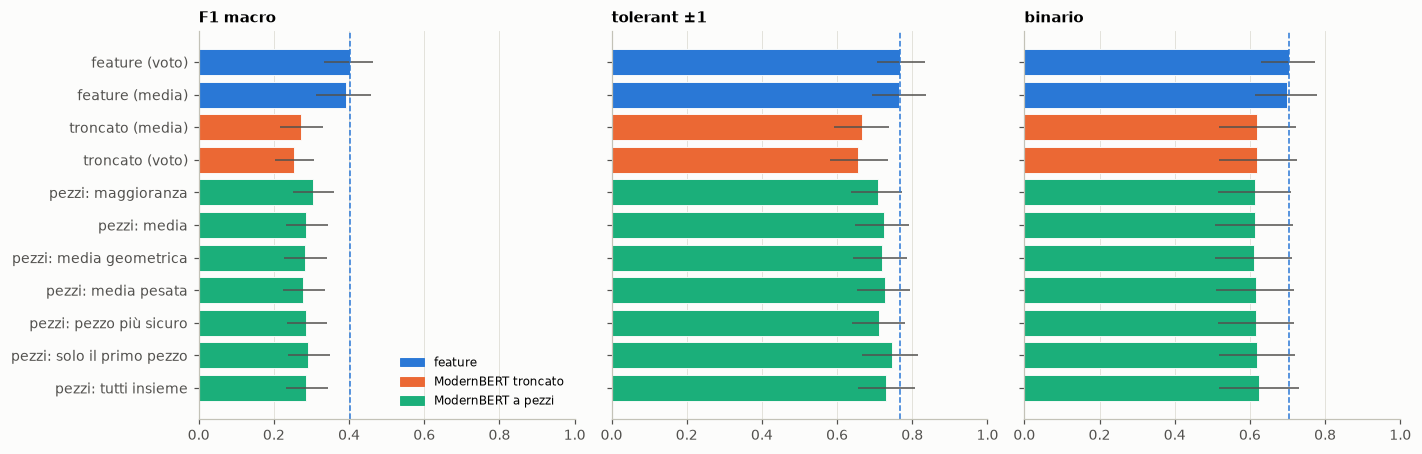

In [14]:
# 6.2 le tre metriche in un grafico (barre = valore, linee = intervallo al 95%)
colore = [BLU if k.startswith("feature") else ARANCIO if k.startswith("troncato") else VERDE for k in tab.index]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for a, m in zip(ax, ["F1 macro", "tolerant ±1", "binario"]):
    ic = np.array([[float(x) for x in re.findall(r"[\d.]+", s)] for s in tab[f"{m} IC"]])
    a.barh(tab.index[::-1], tab[m][::-1], color=colore[::-1])
    a.errorbar(tab[m][::-1], tab.index[::-1], xerr=[tab[m][::-1] - ic[::-1, 0], ic[::-1, 1] - tab[m][::-1]], fmt="none", ecolor=GRIGIO, lw=1)
    a.axvline(tab.loc["feature (voto)", m], color=BLU, ls="--", lw=1)
    a.set_title(m); a.set_xlim(0, 1)
ax[0].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in [BLU, ARANCIO, VERDE]], ["feature", "ModernBERT troncato", "ModernBERT a pezzi"],
             loc="lower right", fontsize=8)
mostra("6_confronto", "x")

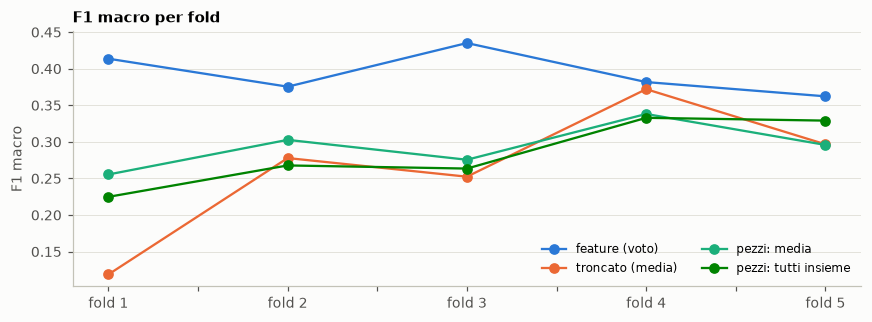

,feature (voto),troncato (media),pezzi: media,pezzi: tutti insieme
fold 1,0.414,0.119,0.255,0.225
fold 2,0.375,0.278,0.303,0.268
fold 3,0.435,0.252,0.276,0.264
fold 4,0.382,0.372,0.338,0.333
fold 5,0.362,0.297,0.296,0.329


In [15]:
# 6.3 F1 per fold: i risultati sono stabili?
scelti = ["feature (voto)", "troncato (media)", "pezzi: media", "pezzi: tutti insieme"]
per_fold = pd.DataFrame({k: [F.metriche(val.label[val.fold == f], prev[k][(val.fold == f).to_numpy()])["F1 macro"] for f in range(1, 6)]
                         for k in scelti}, index=[f"fold {f}" for f in range(1, 6)])
per_fold.to_csv(OUT / "per_fold.csv")
per_fold.plot(marker="o", color=[BLU, ARANCIO, VERDE, "#008300"], figsize=(8, 3))
plt.title("F1 macro per fold"); plt.ylabel("F1 macro"); plt.legend(fontsize=8, ncol=2)
mostra("6_per_fold")
per_fold.round(3)

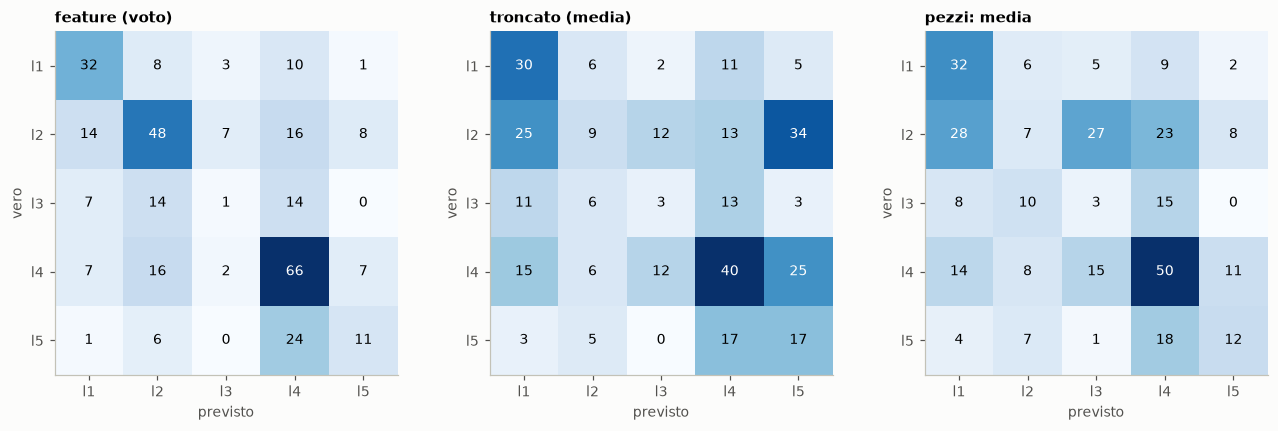

In [16]:
# 6.4 matrici di confusione (righe: livello vero; colonne: livello previsto)
scelti = ["feature (voto)", "troncato (media)", "pezzi: media"]
fig, assi = plt.subplots(1, 3, figsize=(12, 3.8))
for a, k in zip(assi, scelti):
    M = pd.crosstab(pd.Series(val.label.to_numpy()), pd.Series(prev[k])).reindex(index=range(5), columns=range(5), fill_value=0)
    a.imshow(M, cmap="Blues"); a.grid(False)
    for i in range(5):
        for j in range(5):
            a.text(j, i, M.iloc[i, j], ha="center", va="center", fontsize=9, color="white" if M.iloc[i, j] > M.values.max() / 2 else "black")
    a.set_xticks(range(5), F.LIVELLI); a.set_yticks(range(5), F.LIVELLI); a.set_title(k)
    a.set_xlabel("previsto"); a.set_ylabel("vero")
plt.tight_layout(); plt.savefig(GRAFICI / "6_confusione.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. In breve

In [17]:
# 7.1 i numeri principali
f1 = tab["F1 macro"]
pezzi = f1[f1.index.str.startswith("pezzi")]
print(f"- testo perso da ModernBERT: il {(art.token > 1022).mean():.0%} degli articoli supera i 1024 token; resta fuori il {fuori.sum() / art.token.sum():.0%} dei token")
print(f"- F1 macro: feature {f1['feature (voto)']:.3f}; ModernBERT troncato {f1['troncato (media)']:.3f}; a pezzi da {pezzi.min():.3f} a {pezzi.max():.3f}")
print(f"- il migliore: {f1.idxmax()} ({f1.max():.3f})")
print(f"- solo il primo pezzo in test: {f1['pezzi: solo il primo pezzo']:.3f}")
print(f"- binario: da {tab.binario.min():.3f} a {tab.binario.max():.3f}; tolerant ±1: da {tab['tolerant ±1'].min():.3f} a {tab['tolerant ±1'].max():.3f}")
tab.loc[pezzi.index, ["ΔF1 vs feature (voto)", "ΔF1 vs troncato (media)"]]

- testo perso da ModernBERT: il 40% degli articoli supera i 1024 token; resta fuori il 35% dei token
- F1 macro: feature 0.403; ModernBERT troncato 0.272; a pezzi da 0.278 a 0.303
- il migliore: feature (voto) (0.403)
- solo il primo pezzo in test: 0.292
- binario: da 0.610 a 0.703; tolerant ±1: da 0.656 a 0.768


,ΔF1 vs feature (voto),ΔF1 vs troncato (media)
modello,,
pezzi: maggioranza,-0.100 [-0.171; -0.021],+0.032 [-0.024; +0.086]
pezzi: media,-0.118 [-0.187; -0.037],+0.013 [-0.033; +0.060]
pezzi: media geometrica,-0.120 [-0.190; -0.040],+0.011 [-0.034; +0.057]
pezzi: media pesata,-0.125 [-0.193; -0.043],+0.006 [-0.039; +0.052]
pezzi: pezzo più sicuro,-0.116 [-0.185; -0.037],+0.015 [-0.031; +0.060]
pezzi: solo il primo pezzo,-0.111 [-0.180; -0.032],+0.020 [-0.029; +0.071]
pezzi: tutti insieme,-0.117 [-0.183; -0.041],+0.014 [-0.033; +0.061]
